In [ ]:
# Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
# Load Dataset

In [2]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

print("Training Dataset:", train_data.shape)
print("Testing Dataset:", test_data.shape)

Training Dataset: (27455, 785)
Testing Dataset: (7172, 785)


In [ ]:
# Separate Input Features and Target Labels

In [3]:
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [ ]:
# Data Normalization

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
# Reshape Images and Encode Labels

In [5]:
X_train = X_train.reshape(-1, 28, 28)
X_test = X_test.reshape(-1, 28, 28)

classes = np.unique(np.concatenate((y_train, y_test)))

label_mapping = {
    label: index for index, label in enumerate(classes)
}

y_train = np.array([label_mapping[label] for label in y_train])
y_test = np.array([label_mapping[label] for label in y_test])

num_classes = len(classes)

print("Number of Classes:", num_classes)

Number of Classes: 24


#### above common for all

### CHIT 1 , CHIT 2: Training Accuracy, Testing Accuracy and Loss Graph

In [ ]:
# Build Feedforward Neural Network (FNN)

In [6]:
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(num_classes, activation='softmax')
])

model.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,296 (430.84 KB)

 Trainable params: 110,296 (430.84 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the Model

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Model Training

In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.2710 - loss: 2.5138 - val_accuracy: 0.3853 - val_loss: 1.9198
Epoch 2/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.5216 - loss: 1.5645 - val_accuracy: 0.5222 - val_loss: 1.4476
Epoch 3/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.6200 - loss: 1.2242 - val_accuracy: 0.6453 - val_loss: 1.1453
Epoch 4/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6806 - loss: 1.0289 - val_accuracy: 0.6333 - val_loss: 1.0301
Epoch 5/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7354 - loss: 0.8668 - val_accuracy: 0.6996 - val_loss: 0.8944
Epoch 6/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7732 - loss: 0.7438 - val_accuracy: 0.7731 - val_loss: 0.7049
Epoch 7/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8084 - loss: 0.6313 - val_accuracy: 0.7586 - val_loss: 0.7315
Epoch 8/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8390 - loss: 0.5397 - val_accu

### Calculate Training Accuracy

In [9]:
train_loss, train_accuracy = model.evaluate(
    X_train, y_train
)

print("Training Accuracy:", train_accuracy * 100, "%")

858/858 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8660 - loss: 0.4298
Training Accuracy: 86.5998923778534 %


### Plot Training and Validation Accuracy Graph

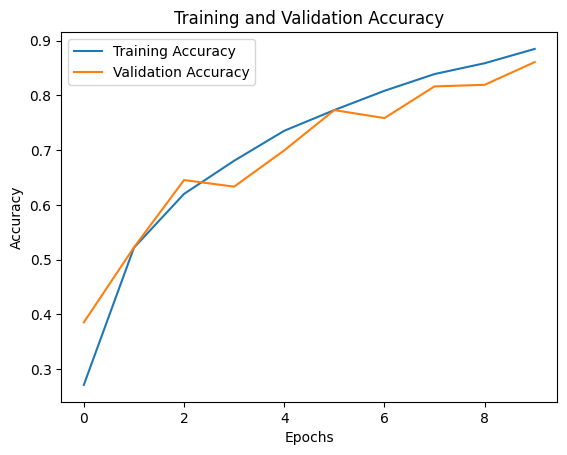

In [10]:
plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

### Plot Training and Validation Loss Graph

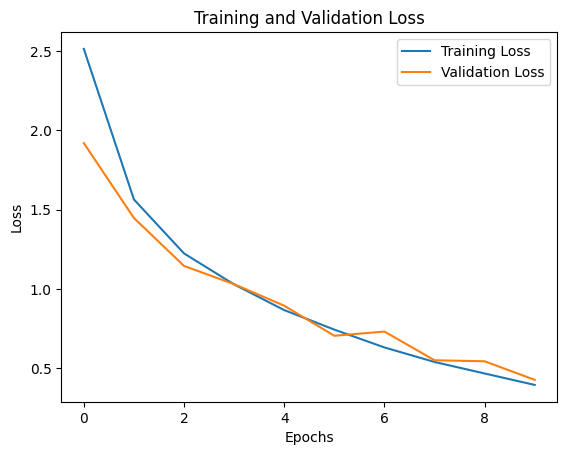

In [11]:
plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.show()

#### CHIT 3: Display Five Predictions

In [ ]:
# Predict Five Test Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step


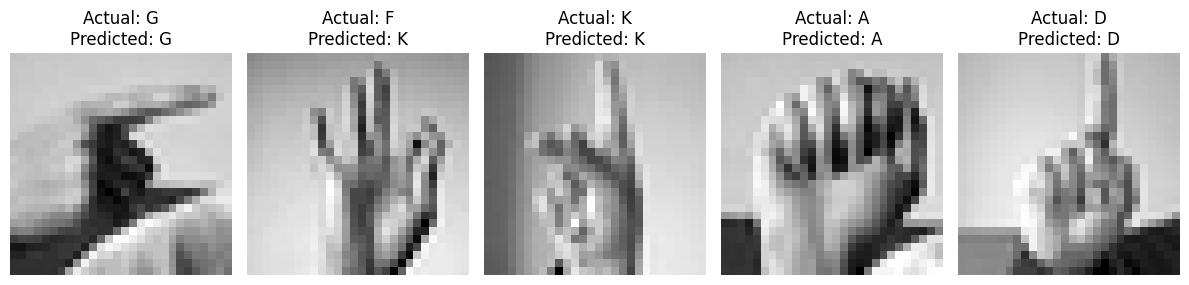

In [12]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

alphabet = [
    chr(label + 65)
    for label in classes
]

plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i], cmap='gray')

    actual = alphabet[y_test[i]]
    predicted = alphabet[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

#### CHIT 5: Confusion Matrix

In [ ]:
# Generate Confusion Matrix

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


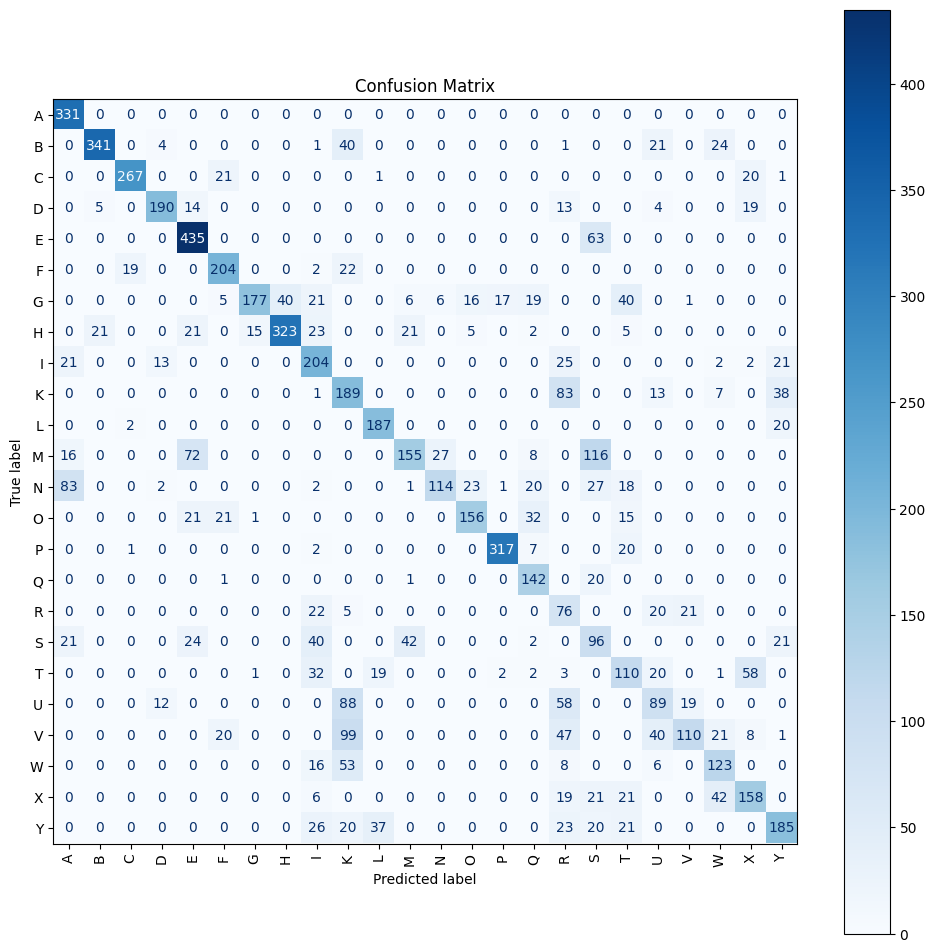

In [13]:
y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=alphabet
)

fig, ax = plt.subplots(figsize=(12, 12))

display.plot(cmap='Blues', ax=ax, xticks_rotation='vertical')

plt.title("Confusion Matrix")
plt.show()

FNN – Code-Based Viva (Practicals 1–5)
A. Importing Libraries
1. Why do we import NumPy?

To perform numerical operations and handle arrays.

2. Why do we use Pandas?

To load and manipulate the CSV dataset.

3. Why do we import Matplotlib?

To display images and plot accuracy and loss graphs.

4. What is TensorFlow?

TensorFlow is a deep learning framework used to build and train neural networks.

5. Why do we import Sequential?

To create a neural network layer by layer.
from tensorflow.keras.models import Sequential


6. What is Dense?

Dense creates a fully connected neural network layer.
from tensorflow.keras.layers import Dense


B. Loading and Preprocessing Dataset
7. What does this statement do?
train = pd.read_csv('sign_mnist_train.csv')


It loads the training dataset from a CSV file.

8. What does iloc mean?

It is used to select rows and columns using integer positions.

9. Explain this statement.
X_train = train.iloc[:, 1:].values


It selects all rows and all columns except the first column, which contains labels.

10. Explain this statement.
y_train = train.iloc[:, 0].values


It selects the first column containing alphabet labels.

11. What is X_train?

It contains input image pixel values used for training.

12. What is y_train?

It contains the actual alphabet labels corresponding to training images.

13. Why do we divide by 255?
X_train = X_train / 255.0


To normalize pixel values from 0–255 into 0–1.

14. Why do we use 255 specifically?

Because grayscale pixel values range from 0 to 255.

15. What is the purpose of .values?

It converts the Pandas DataFrame or Series into a NumPy array.
C. Creating FNN Model
16. What does Sequential mean?

It creates a neural network in which layers are arranged sequentially.

17. Explain this statement.
Dense(128, activation='relu')


It creates a fully connected layer containing 128 neurons with ReLU activation.

18. What does 128 represent?

The number of neurons in that Dense layer.

19. Why do we use ReLU?

It introduces non-linearity and converts negative values into zero.

20. Explain this statement.
Dense(64, activation='relu')


It creates another hidden layer with 64 neurons.

21. What is the output layer?
Dense(num_classes, activation='softmax')


It produces probabilities for all alphabet classes.

22. Why do we use Softmax?

To convert output values into class probabilities.

23. Why is the input shape 784?

Because 28 × 28 pixels become 784 values after flattening.

24. What is the difference between hidden and output layers?

Hidden layers learn patterns, while the output layer predicts the final class.
D. Compiling and Training FNN
25. What is the purpose of model.compile()?

It configures the model with an optimizer, loss function and evaluation metrics.

26. Explain this statement.
optimizer='adam'


Adam is an optimization algorithm used to update model weights.

27. What is sparse categorical crossentropy?

It is a loss function used for multiclass classification when labels are represented as integers.

28. What does metrics=['accuracy'] mean?

It tells the model to calculate classification accuracy during training and evaluation.

29. Explain model.fit().
model.fit(X_train, y_train, epochs=10)


It trains the model using input images and their corresponding labels for 10 epochs.

30. What does epochs=10 mean?

The model processes the complete training dataset 10 times.

31. What is batch_size=128?

The model processes 128 training samples before updating its weights.

32. What is validation_split=0.1?

It reserves 10% of the training data for validation.
E. Evaluating and Predicting
33. What does model.evaluate() do?

It evaluates the trained model using test data and returns loss and accuracy.

34. Explain this statement.
predictions = model.predict(X_test[:5])


It predicts the output for the first five test images.

35. What does np.argmax() do?

It returns the index of the highest probability, which represents the predicted class.

36. Why do we use reshape(28,28) while displaying images?

To convert flattened pixel data back into a 28 × 28 image.

37. What does plt.imshow() do?

It displays an image.

38. Why do we use cmap='gray'?

38. Why do we use cmap='gray'?

To display the image in grayscale.

39. What is the purpose of plt.subplot()?

It divides the plotting area into multiple sections to display multiple images.

40. What does plt.axis('off') do?

It hides the axis values and markings.
F. Accuracy, Loss and Confusion Matrix
41. Explain history.history['accuracy'].

It stores training accuracy values after every epoch.

42. Explain history.history['loss'].

It stores training loss values after every epoch.

43. What is validation accuracy?

Accuracy measured on the validation dataset during training.

44. What does plt.plot() do?

It draws a graph using the given data.

45. What is a confusion matrix?

It compares actual and predicted class labels.

46. Explain this statement.
cm = confusion_matrix(y_test, y_pred)


It generates a confusion matrix using actual and predicted labels.

47. What is ConfusionMatrixDisplay?

It is a Scikit-learn utility used to visualize a confusion matrix.